In [28]:
import torch
import torch.nn as nn
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import copy
import pandas as pd 
import torch.nn.functional as F
import numpy as np
import cv2 
from PIL import Image
from torchvision import transforms
import os
from torchmetrics.functional import confusion_matrix
import matplotlib.pyplot as plt
from torchmetrics.classification import MulticlassAUROC

# Load Dataset and Train Model

In [29]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available() and torch.backends.mps.is_built():
        return torch.device("mps")
    else:
        return torch.device("cpu")

device = get_device()
print("Using device:", device)

Using device: mps


In [30]:
TRAIN_ROOT = "data/brain_mri/training"
TEST_ROOT = "data/brain_mri/testing"
train_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT)
test_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT)

In [31]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.vgg16 = models.vgg16(pretrained=True) 

        # Replace output layer 
        in_feats = self.vgg16.classifier[6].in_features 
        # Replace the original classifier[6] with a sequence that includes Dropout.
        self.vgg16.classifier = nn.Sequential(
            *self.vgg16.classifier[:-1], # Keep layers 0 through 5 (which includes 3 Linear layers)
            nn.Dropout(p=0.4),           # ADD DROPOUT HERE 
            nn.Linear(in_feats, 4)       # The final 4-class classification layer
        )

    def forward(self, x):
        x = self.vgg16(x)
        return x

model = CNNModel()
model.to(device)
model

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


CNNModel(
  (vgg16): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=True)
      (16):

In [32]:
train_dataset = torchvision.datasets.ImageFolder(
        root=TRAIN_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

test_dataset = torchvision.datasets.ImageFolder(
        root=TEST_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

In [33]:
batch_size = 32
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [34]:
cross_entropy_loss = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00001, weight_decay=1e-4)
epochs = 10

In [35]:
for epoch in range(epochs):  
    for i, batch in enumerate(train_loader, 0):
        inputs, labels = batch
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        # Labels are automatically one-hot-encoded
        loss = cross_entropy_loss(outputs, labels)
        loss.backward()
        optimizer.step()
        print(loss)


tensor(1.5231, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3125, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.4153, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3443, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3461, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3415, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.1858, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.2533, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3899, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.4119, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3164, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.4116, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3742, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.3228, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.4146, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.1977, device='mps:0', grad_fn=<NllLossBackward0>)
tensor(1.2397, device='mps:0', grad_fn=<NllLossBackward0

In [36]:
torch.save(model, 'brain_tumor_submission_model.pth')

## Evaluate Model Performance

In [37]:
inputs, labels = next(iter(test_loader))
inputs = inputs.to(device)
labels = labels.numpy()
outputs = model(inputs).max(1).indices.detach().cpu().numpy()
comparison = pd.DataFrame()
print("Batch accuracy: ", (labels==outputs).sum()/len(labels))
comparison["labels"] = labels

comparison["outputs"] = outputs
comparison

Batch accuracy:  0.75


,labels,outputs
0,2,2
1,3,3
2,1,1
3,0,2
4,3,3
5,1,1
6,3,3
7,1,1
8,1,1
9,2,2


In [38]:
def calculate_pytorch_metrics(model, data_loader, device, num_classes, class_names):
    """
    Calculates and prints the per-class performance metrics using PyTorch tensors.
    """
    model.eval()
    all_true_labels = []
    all_predictions = []

    # 1. Collect all predictions and true labels
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            
            # Get the predicted class indices
            _, predicted_indices = torch.max(outputs, 1)

            all_true_labels.append(labels.cpu())
            all_predictions.append(predicted_indices.cpu())

    # Concatenate all lists into single tensors
    true_labels = torch.cat(all_true_labels)
    predictions = torch.cat(all_predictions)

    # 2. Calculate the Confusion Matrix
    # The confusion matrix C is where C[i][j] is the number of samples
    # known to be in class i and predicted to be in class j.
    conf_matrix = confusion_matrix(predictions, true_labels, task='multiclass', num_classes=num_classes)
    
    # 3. Calculate Performance Metrics from the Confusion Matrix
    
    print("\n--- Pure PyTorch Per-Class Metrics ---")
    print("Class | Precision | Recall | F1-Score | Support")
    print("-------------------------------------------------")

    for i in range(num_classes):
        # True Positives (TP): Correctly predicted class i
        TP = conf_matrix[i, i].item()
        
        # False Positives (FP): Predicted class i, but the true class was not i (sum of column i excluding TP)
        FP = conf_matrix[:, i].sum().item() - TP
        
        # False Negatives (FN): True class was i, but predicted as something else (sum of row i excluding TP)
        FN = conf_matrix[i, :].sum().item() - TP
        
        # Support (Actual count for class i)
        support = conf_matrix[i, :].sum().item()

        # Calculate metrics
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        
        print(f"{class_names[i]:<5} | {precision:.4f} | {recall:.4f} | {f1_score:.4f} | {support:<7}")
        
    print("-------------------------------------------------")
    
    
# NOTE: If you don't want to use torchmetrics, you can calculate the confusion matrix 
# manually using loops or PyTorch's `scatter_add_` function, but it is complex.

In [39]:
calculate_pytorch_metrics(
    model=model,
    data_loader=test_loader,
    device=device,
    num_classes=len(test_dataset.classes),
    class_names=test_dataset.classes
)


--- Pure PyTorch Per-Class Metrics ---
Class | Precision | Recall | F1-Score | Support
-------------------------------------------------
glioma_tumor | 1.0000 | 0.2300 | 0.3740 | 100    
meningioma_tumor | 0.6552 | 0.9913 | 0.7889 | 115    
no_tumor | 0.7955 | 1.0000 | 0.8861 | 105    
pituitary_tumor | 0.9538 | 0.8378 | 0.8921 | 74     
-------------------------------------------------


In [40]:
def plot_multiclass_auroc(model, data_loader, device, num_classes, class_names):
    """
    Calculates and prints the macro and weighted average AUC for a multi-class model.
    """
    model.eval()
    all_true_labels = []
    all_logits = [] # Collect raw model outputs (logits)

    print("--- Starting AUC Calculation ---")
    
    # 1. Collect all labels and logits
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            # Forward pass: outputs are the raw logits
            outputs = model(inputs)

            all_true_labels.append(labels.cpu())
            all_logits.append(outputs.cpu())

    # Concatenate all lists into single tensors
    true_labels = torch.cat(all_true_labels)
    logits = torch.cat(all_logits)

    # 2. Calculate AUC Scores using MulticlassAUROC
    
    # Initialize AUROC metric for Macro Average
    auroc_macro = MulticlassAUROC(
        num_classes=num_classes, 
        average='macro'
    )
    
    # Initialize AUROC metric for Weighted Average
    auroc_weighted = MulticlassAUROC(
        num_classes=num_classes, 
        average='weighted'
    )
    
    # Initialize AUROC metric for Per-Class Scores (used for plotting)
    auroc_none = MulticlassAUROC(
        num_classes=num_classes, 
        average='none' # 'none' returns score for each cla
    )

    # Compute the scores
    macro_auroc = auroc_macro(logits, true_labels)
    weighted_auroc = auroc_weighted(logits, true_labels)
    per_class_auroc = auroc_none(logits, true_labels)
    
    # 3. Print Results
    print("\nAUC Scores:")
    print(f"  Macro Average AUC:   {macro_auroc.item():.4f} (Treats all classes equally)")
    print(f"  Weighted Average AUC: {weighted_auroc.item():.4f} (Weights classes by support/count)")
    
    print("\nPer-Class AUC Scores:")
    for name, score in zip(class_names, per_class_auroc):
        print(f"  - {name:<20}: {score:.4f}")
        
    # 4. Plotting the results
    
    # Create labels for the bar chart
    labels = class_names + ['Macro Avg', 'Weighted Avg']
    scores = per_class_auroc.tolist() + [macro_auroc.item(), weighted_auroc.item()]
    colors = ['skyblue'] * num_classes + ['gold', 'coral']

    plt.figure(figsize=(10, 6))
    plt.bar(labels, scores, color=colors)
    plt.axhline(y=0.5, color='r', linestyle='--', label='Random Guess (AUC=0.5)')
    
    plt.ylim(0.0, 1.0) # AUC range is 0 to 1
    plt.ylabel("AUC Score")
    plt.title("Multiclass Area Under the ROC Curve (AUROC)")
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()

--- Starting AUC Calculation ---

AUC Scores:
  Macro Average AUC:   0.9352 (Treats all classes equally)
  Weighted Average AUC: 0.9335 (Weights classes by support/count)

Per-Class AUC Scores:
  - glioma_tumor        : 0.7984
  - meningioma_tumor    : 0.9645
  - no_tumor            : 0.9896
  - pituitary_tumor     : 0.9884


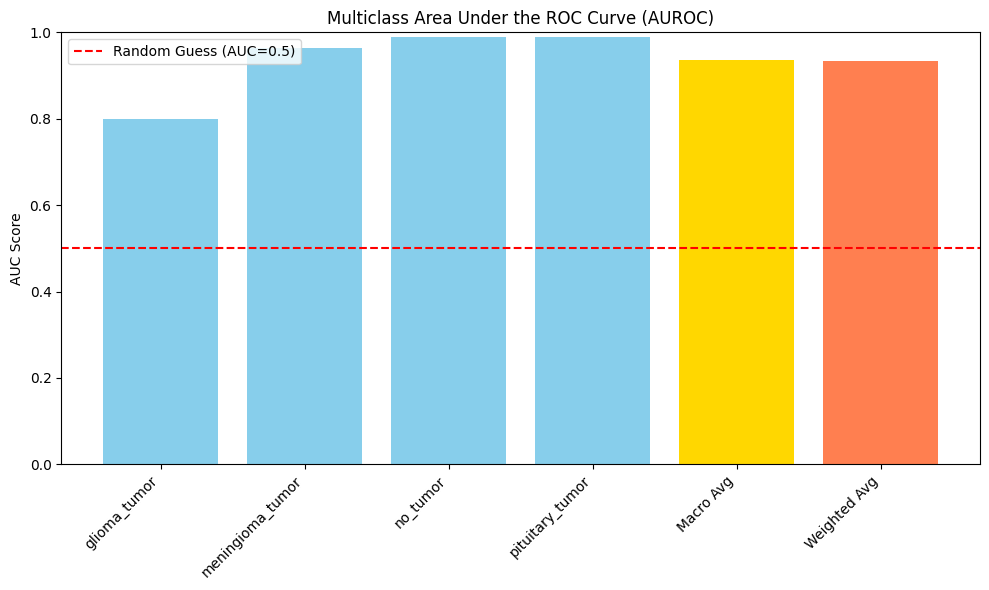

In [41]:
plot_multiclass_auroc(
    model=model,
    data_loader=test_loader,
    device=device,
    num_classes=len(test_dataset.classes),
    class_names=test_dataset.classes
)

In [42]:
def export_predictions_to_csv_with_paths(model, data_loader, device, class_names, dataset, output_filename='predictions_analysis_with_paths.csv'):
    """
    Runs the model and exports a CSV with Target Class, Predicted Class, and the File Path.
    """
    model.eval()
    
    # Get the class-to-index mapping from the dataset
    print(f"Dataset class_to_idx mapping: {dataset.class_to_idx}")
    print(f"Your class_names list: {class_names}")
    
    # Lists to store the results
    results = {
        'File_Path': [],
        'Actual_Class': [],
        'Predicted_Class': []
    }
    
    current_index = 0  # Track the index of the sample in the entire dataset

    print("--- Starting prediction export with file paths ---")
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            batch_size = inputs.size(0)
            
            inputs = inputs.to(device)
            
            # Forward pass
            outputs = model(inputs)
            _, predicted_indices = torch.max(outputs, 1)

            # Move true labels and predictions to CPU
            true_labels_cpu = labels.cpu().numpy()
            predicted_indices_cpu = predicted_indices.cpu().numpy()

            # Process the batch results
            for i in range(batch_size):
                sample_index = current_index + i
                true_idx = true_labels_cpu[i]
                pred_idx = predicted_indices_cpu[i]
                
                # Get file path from dataset.samples
                file_path = dataset.samples[sample_index][0]
                
                # Append the data
                results['File_Path'].append(file_path)
                results['Actual_Class'].append(class_names[true_idx])
                results['Predicted_Class'].append(class_names[pred_idx])
                
            current_index += batch_size

    # Create and Save the DataFrame
    df_results = pd.DataFrame(results)
    df_results.to_csv(output_filename, index=False)

    # Print confirmation and sample
    print(f"\n Successfully exported {len(df_results)} predictions with paths to: {os.path.abspath(output_filename)}")
    print(f"\nFirst 5 rows preview:")
    print(df_results.head())
    
    # Print accuracy
    correct = (df_results['Actual_Class'] == df_results['Predicted_Class']).sum()
    accuracy = correct / len(df_results) * 100
    print(f"\nAccuracy: {correct}/{len(df_results)} ({accuracy:.2f}%)")
    
    return df_results


# Usage example:
class_names = list(test_dataset.class_to_idx.keys())  # Get from dataset directly
print(f"Class names (in correct order): {class_names}")



Class names (in correct order): ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [43]:
# Export predictions
df = export_predictions_to_csv_with_paths(
    model=model,
    data_loader=test_loader,
    device=device,
    class_names=class_names,
    dataset=test_dataset,  # Pass the dataset instead of file paths
    output_filename='predictions_with_paths.csv'
)

Dataset class_to_idx mapping: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Your class_names list: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
--- Starting prediction export with file paths ---

 Successfully exported 394 predictions with paths to: /Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/Assignment-2/predictions_with_paths.csv

First 5 rows preview:
                                           File_Path      Actual_Class  \
0   data/brain_mri/testing/glioma_tumor/image(1).jpg          no_tumor   
1  data/brain_mri/testing/glioma_tumor/image(10).jpg  meningioma_tumor   
2  data/brain_mri/testing/glioma_tumor/image(100)...   pituitary_tumor   
3  data/brain_mri/testing/glioma_tumor/image(11).jpg          no_tumor   
4  data/brain_mri/testing/glioma_tumor/image(12).jpg          no_tumor   

    Predicted_Class  
0          no_tumor  
1  meningioma_tumor  
2   pituitary_tumor  
3          no_tumor  
4   

## Use LRP To Explain The Model

In [44]:
def new_layer(layer, g):
    """Clone a layer and pass its parameters through the function g."""
    layer = copy.deepcopy(layer)
    try: layer.weight = torch.nn.Parameter(g(layer.weight))
    except AttributeError: pass
    try: layer.bias = torch.nn.Parameter(g(layer.bias))
    except AttributeError: pass
    return layer


In [45]:
def dense_to_conv(layers):
    """ Converts a dense layer to a conv layer """
    newlayers = []
    for i,layer in enumerate(layers):
        if isinstance(layer, nn.Linear):
            newlayer = None
            if i == 0:
                m, n = 512, layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,7)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,7,7))
            else:
                m,n = layer.weight.shape[1],layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,1)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,1,1))
            newlayer.bias = nn.Parameter(layer.bias)
            newlayers += [newlayer]
        else:
            newlayers += [layer]
    return newlayers


In [46]:
def get_linear_layer_indices(model):
    offset = len(model.vgg16._modules['features']) + 1
    indices = []
    for i, layer in enumerate(model.vgg16._modules['classifier']): 
        if isinstance(layer, nn.Linear): 
            indices.append(i)
    indices = [offset + val for val in indices]
    return indices


In [47]:
def apply_lrp_on_vgg16(model, image):
    image = torch.unsqueeze(image, 0)
    # >>> Step 1: Extract layers
    layers = list(model.vgg16._modules['features']) \
                + [model.vgg16._modules['avgpool']] \
                + dense_to_conv(list(model.vgg16._modules['classifier']))
    linear_layer_indices = get_linear_layer_indices(model)
    # >>> Step 2: Propagate image through layers and store activations
    n_layers = len(layers)
    activations = [image] + [None] * n_layers # list of activations
    
    for layer in range(n_layers):
        if layer in linear_layer_indices:
            if layer == 32:
                activations[layer] = activations[layer].reshape((1, 512, 7, 7))
        activation = layers[layer].forward(activations[layer])
        if isinstance(layers[layer], torch.nn.modules.pooling.AdaptiveAvgPool2d):
            activation = torch.flatten(activation, start_dim=1)
        activations[layer+1] = activation

    # >>> Step 3: Replace last layer with one-hot-encoding
    output_activation = activations[-1].detach().cpu().numpy()
    max_activation = output_activation.max()
    one_hot_output = [val if val == max_activation else 0 
                        for val in output_activation[0]]

    activations[-1] = torch.FloatTensor([one_hot_output]).to(device)

    # >>> Step 4: Backpropagate relevance scores
    relevances = [None] * n_layers + [activations[-1]]
    # Iterate over the layers in reverse order
    for layer in range(0, n_layers)[::-1]:
        current = layers[layer]
        # Treat max pooling layers as avg pooling
        if isinstance(current, torch.nn.MaxPool2d):
            layers[layer] = torch.nn.AvgPool2d(2)
            current = layers[layer]
        if isinstance(current, torch.nn.Conv2d) or \
           isinstance(current, torch.nn.AvgPool2d) or\
           isinstance(current, torch.nn.Linear):
            activations[layer] = activations[layer].data.requires_grad_(True)
            
            # Apply variants of LRP depending on the depth
            # see: https://link.springer.com/chapter/10.1007%2F978-3-030-28954-6_10
            # Lower layers, LRP-gamma >> Favor positive contributions (activations)
            if layer <= 16:       rho = lambda p: p + 0.25*p.clamp(min=0); incr = lambda z: z+1e-9
            # Middle layers, LRP-epsilon >> Remove some noise / Only most salient factors survive
            if 17 <= layer <= 30: rho = lambda p: p;                       incr = lambda z: z+1e-9+0.25*((z**2).mean()**.5).data
            # Upper Layers, LRP-0 >> Basic rule
            if layer >= 31:       rho = lambda p: p;                       incr = lambda z: z+1e-9
            
            # Transform weights of layer and execute forward pass
            z = incr(new_layer(layers[layer],rho).forward(activations[layer]))
            # Element-wise division between relevance of the next layer and z
            s = (relevances[layer+1]/z).data                                     
            # Calculate the gradient and multiply it by the activation
            (z * s).sum().backward(); 
            c = activations[layer].grad       
            # Assign new relevance values           
            relevances[layer] = (activations[layer]*c).data                          
        else:
            relevances[layer] = relevances[layer+1]

    # >>> Potential Step 5: Apply different propagation rule for pixels
    return relevances[0]

In [93]:
# Calculate relevances for first image in this test batch
image_id = 2
image_relevances = apply_lrp_on_vgg16(model, inputs[image_id])
image_relevances = image_relevances.permute(0,2,3,1).detach().cpu().numpy()[0]
image_relevances = np.interp(image_relevances, (image_relevances.min(),
                                                image_relevances.max()), 
                                                (0, 1))

/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_32944/3502693049.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  activations[-1] = torch.FloatTensor([one_hot_output]).to(device)


In [94]:
pred_label = list(test_dataset.class_to_idx.keys())[
             list(test_dataset.class_to_idx.values())
            .index(labels[image_id])]
if outputs[image_id] == labels[image_id]:
    print("Groundtruth for this image: ", pred_label)

    # Plot images next to each other
    plt.axis('off')
    plt.subplot(1,2,1)
    plt.imshow(image_relevances[:,:,0], cmap="seismic")
    plt.subplot(1,2,2)
    plt.imshow(inputs[image_id].permute(1,2,0).detach().cpu().numpy())
    plt.show()
else:
    print("This image is not classified correctly.")

This image is not classified correctly.


## Using GRADCAM to explain the model

In [50]:
class SimpleGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)
    
    def save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def __call__(self, input_tensor, target_class=None):
        # Get device from input
        device = input_tensor.device
        
        self.model.eval()
        output = self.model(input_tensor)
        
        if target_class is None:
            target_class = output.argmax(dim=1).item()
        
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0, target_class] = 1
        output.backward(gradient=one_hot, retain_graph=True)
        
        gradients = self.gradients[0]
        activations = self.activations[0]
        weights = torch.mean(gradients, dim=(1, 2))
        
        # Create cam on the same device as activations
        cam = torch.zeros(activations.shape[1:], dtype=torch.float32, device=device)
        for i, w in enumerate(weights):
            cam += w * activations[i]
        
        cam = F.relu(cam)
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        
        return cam.cpu().numpy(), target_class  # Move to CPU only at the end

In [51]:
def visualize_gradcam(image_tensor, cam, prediction, true_label, class_names, save_path=None):
    """
    Create Grad-CAM visualization
    """
    # Convert tensor to numpy
    img = image_tensor.cpu().permute(1, 2, 0).numpy()
    img = (img * 255).astype(np.uint8)
    
    # Resize CAM to match image
    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))
    
    # Create heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    
    # Overlay
    overlayed = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)
    
    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(img)
    axes[0].set_title('Original Image', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(cam, cmap='jet')
    axes[1].set_title('Grad-CAM Heatmap', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(overlayed)
    pred_name = class_names[prediction]
    true_name = class_names[true_label]
    correct = "✓" if prediction == true_label else "✗"
    axes[2].set_title(f'Overlay {correct}\nPred: {pred_name}\nTrue: {true_name}', 
                      fontsize=14, fontweight='bold')
    axes[2].axis('off')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()

In [52]:
# Define your class names (update based on your dataset structure)
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Initialize Grad-CAM with the last convolutional layer of VGG16
target_layer = model.vgg16.features[28]  # Last conv layer
gradcam = SimpleGradCAM(model, target_layer)

# Visualize some samples from test set
model.eval()
num_samples = 5  # Number of samples to visualize

# Get test samples
test_iter = iter(test_loader)
images, labels = next(test_iter)


Generating Grad-CAM visualizations for 5 samples...



/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/nn/modules/module.py:1866: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


Saved: gradcam_sample_0.png


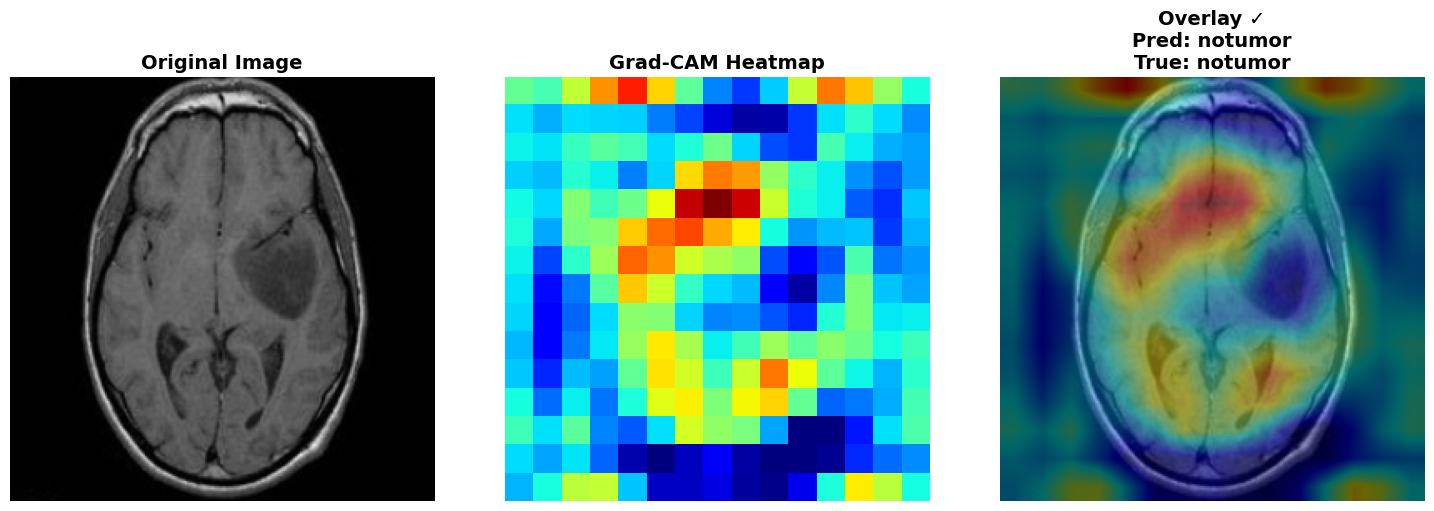

Sample 0: Predicted=notumor, True=notumor
Saved: gradcam_sample_1.png


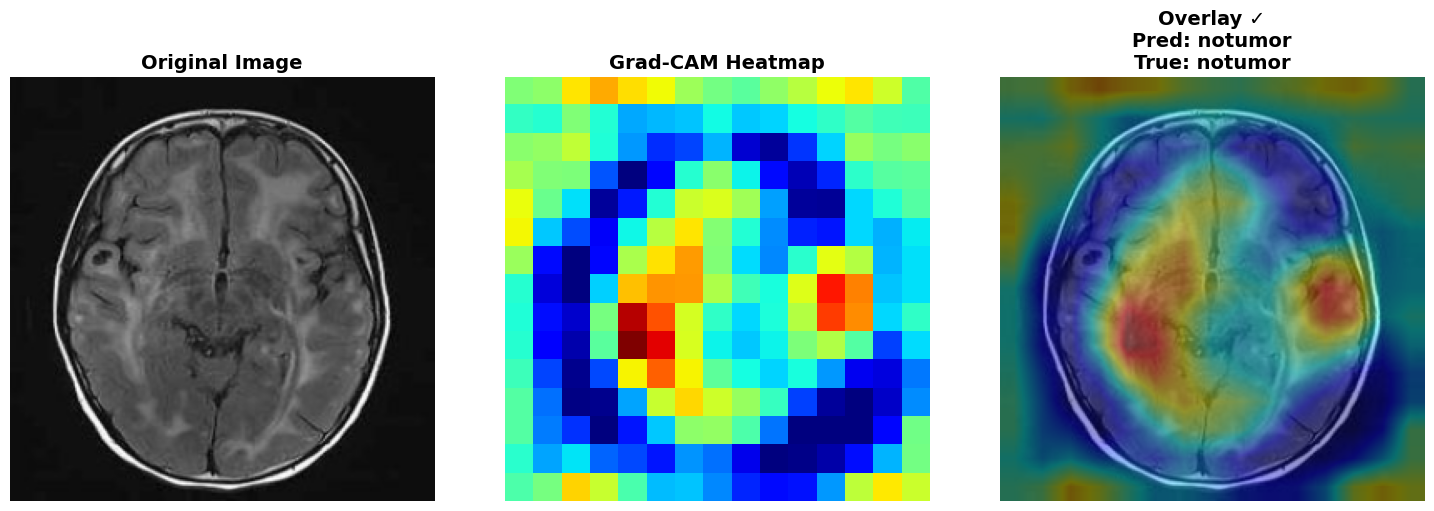

Sample 1: Predicted=notumor, True=notumor
Saved: gradcam_sample_2.png


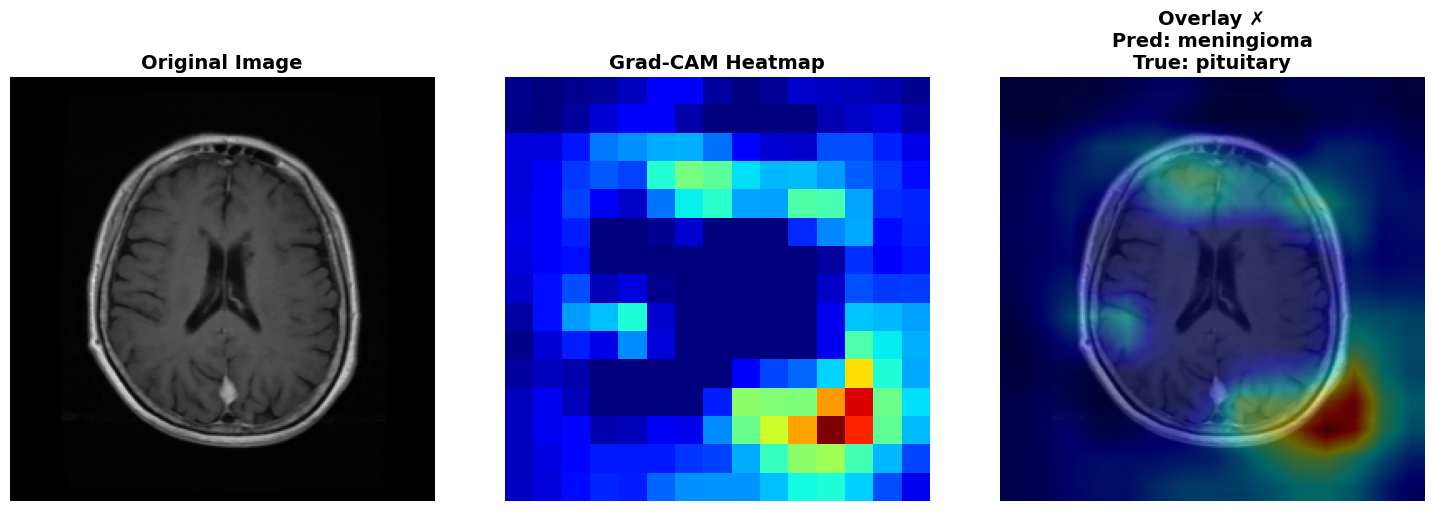

Sample 2: Predicted=meningioma, True=pituitary
Saved: gradcam_sample_3.png


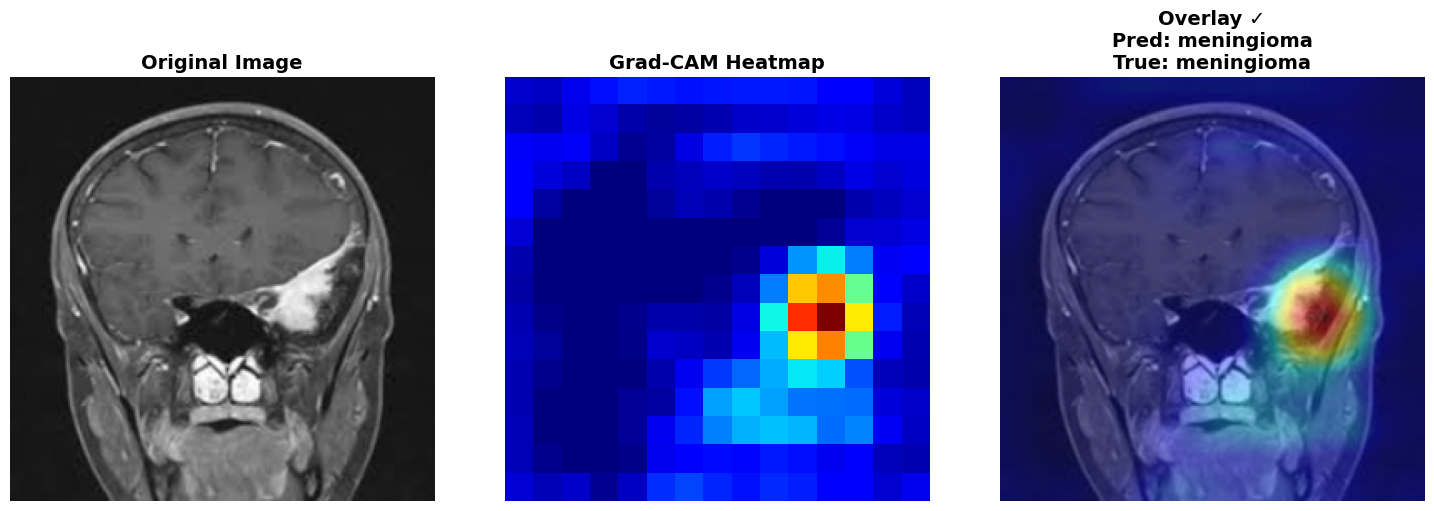

Sample 3: Predicted=meningioma, True=meningioma
Saved: gradcam_sample_4.png


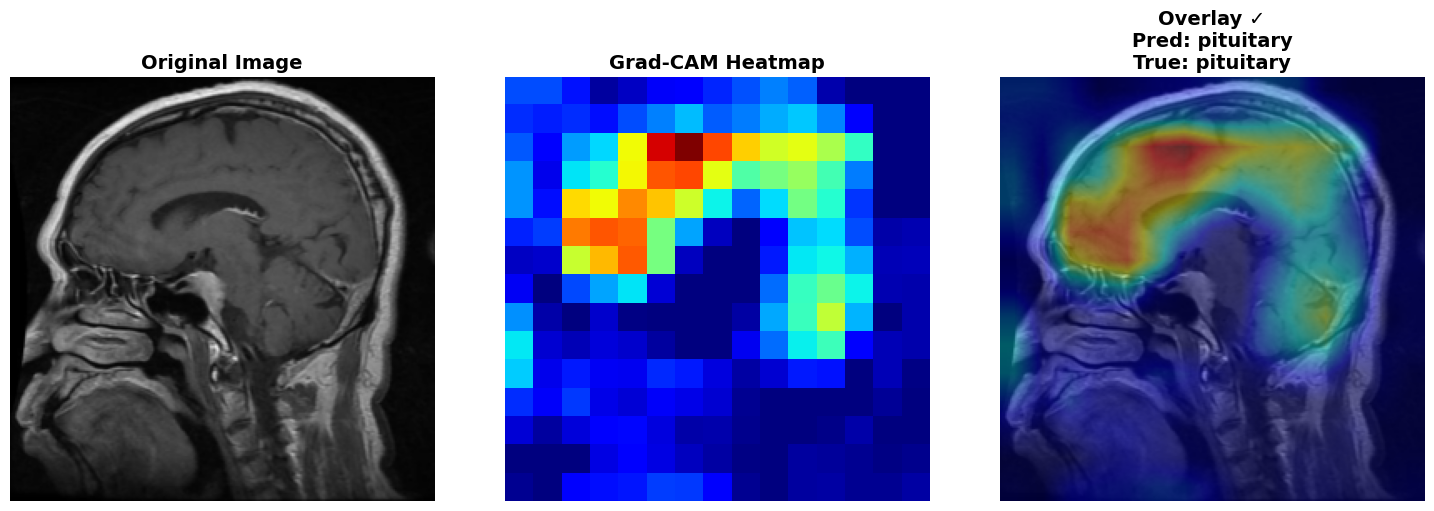

Sample 4: Predicted=pituitary, True=pituitary

✓ Grad-CAM visualization complete!


In [53]:
print(f"\nGenerating Grad-CAM visualizations for {num_samples} samples...\n")

for idx in range(min(num_samples, len(images))):
    # Prepare input
    input_tensor = images[idx:idx+1].to(device)
    true_label = labels[idx].item()
    
    # Generate Grad-CAM
    cam, prediction = gradcam(input_tensor)
    
    # Visualize
    visualize_gradcam(
        images[idx],
        cam,
        prediction,
        true_label,
        class_names,
        save_path=f'gradcam_sample_{idx}.png'
    )
    
    print(f"Sample {idx}: Predicted={class_names[prediction]}, True={class_names[true_label]}")

print("\n✓ Grad-CAM visualization complete!")

In [54]:
def visualize_single_image(image_path, model, device, class_names):
    """
    Apply Grad-CAM to a single image file
    
    Usage:
        visualize_single_image('path/to/image.jpg', model, device, class_names)
    """
    from PIL import Image
    import torchvision.transforms as transforms
    
    # Load and transform image
    transform = transforms.Compose([
        transforms.Resize((255, 255)),
        transforms.ToTensor()
    ])
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)
    
    # Generate Grad-CAM
    target_layer = model.vgg16.features[28]
    gradcam = SimpleGradCAM(model, target_layer)
    cam, prediction = gradcam(input_tensor)
    
    # Visualize
    img_np = np.array(image.resize((255, 255)))
    cam_resized = cv2.resize(cam, (255, 255))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlayed = cv2.addWeighted(img_np, 0.6, heatmap, 0.4, 0)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_np)
    axes[0].set_title('Original', fontsize=14)
    axes[0].axis('off')
    
    axes[1].imshow(cam, cmap='jet')
    axes[1].set_title('Heatmap', fontsize=14)
    axes[1].axis('off')
    
    axes[2].imshow(overlayed)
    axes[2].set_title(f'Prediction: {class_names[prediction]}', fontsize=14)
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.savefig('single_image_gradcam.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return prediction, class_names[prediction]

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/nn/modules/module.py:1866: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


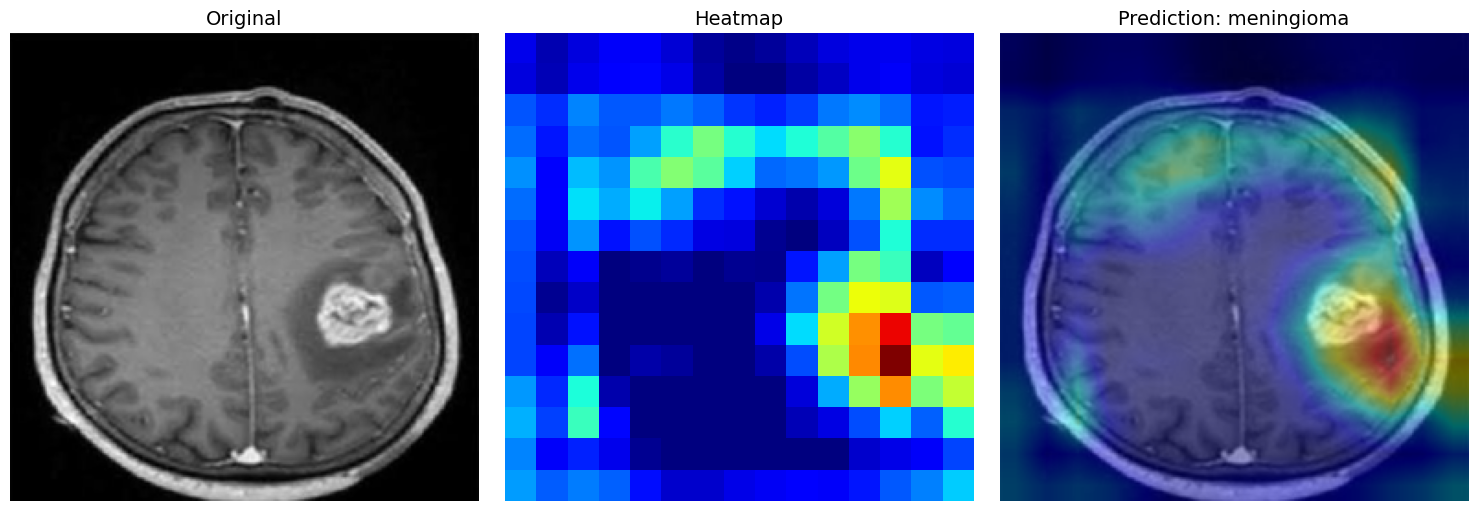

(1, 'meningioma')

In [95]:
visualize_single_image(image_path='data/brain_mri/Testing/glioma_tumor/image(34).jpg',
                       model=model,
                       device=device,
                       class_names=class_names)